# BERT training experiments and final selection
## 1. Introduction
BERT-base-uncased is the first encoder investigated. Controlled runs explore learning
rate and maximum training duration. Selection uses SUM validation data only; neither
SUM test nor UMWP is loaded here. Precision, recall and F1 use UNANSWERABLE as the
positive class. The selected model will later be evaluated on untouched SUM test and
external UMWP data. Epoch budgets below are maxima, subject to early stopping.


## 2. Load experiment results
Read the existing configurations, histories and validation reports. Run 01 has no
standalone config file, so its report's configuration is used. Loading all runs here
does not imply comparing them before their chronological introduction.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'results/bert/run_01').is_dir())
RUN_NAMES = [f'run_{i:02d}' for i in range(1, 5)]
runs = {}
for name in RUN_NAMES:
    folder = ROOT / 'results/bert' / name
    if not folder.is_dir():
        raise FileNotFoundError(folder)
    report_path = folder / 'validation_metrics.json'
    history_path = folder / 'training_history.csv'
    report = json.loads(report_path.read_text(encoding='utf-8'))
    config_path = folder / 'config.json'
    config = dict(report['configuration'])
    if config_path.exists():
        config.update(json.loads(config_path.read_text(encoding='utf-8')))
    runs[name] = dict(config=config, report=report, history=pd.read_csv(history_path))
    print(name, ': loaded history and validation report;',
          'config.json loaded' if config_path.exists() else 'configuration from validation report')

def epoch_table(name):
    history = runs[name]['history']
    columns = ['loss', 'eval_loss', 'eval_accuracy', 'eval_precision', 'eval_recall', 'eval_f1']
    # Trainer stores training/evaluation events in separate rows. Exclude final
    # aggregate logs and combine non-null epoch events, without forward filling.
    events = history.loc[history[columns].notna().any(axis=1), ['epoch', *columns]]
    return events.groupby('epoch', sort=True)[columns].last().rename(columns={'loss': 'train_loss'})

def comparison(names):
    rows = []
    for name in names:
        c = runs[name]['config']
        m = runs[name]['report']['best_validation_metrics']
        rows.append(dict(run=name, learning_rate=c['learning_rate'],
                         max_epochs=c['max_epochs'], batch_size=c['batch_size'],
                         **{f'best_validation_{key}': m[f'eval_{key}']
                            for key in ['accuracy', 'precision', 'recall', 'f1']}))
    return pd.DataFrame(rows).set_index('run')

def show_run(name):
    display(pd.Series(runs[name]['config'], name='configuration').to_frame())
    display(epoch_table(name))
    print('Metrics after reloading the validation-selected checkpoint:')
    display(pd.Series(runs[name]['report']['best_validation_metrics']).to_frame('value'))


run_01 : loaded history and validation report; configuration from validation report
run_02 : loaded history and validation report; config.json loaded
run_03 : loaded history and validation report; config.json loaded
run_04 : loaded history and validation report; config.json loaded


## 3. Run 01 ? Initial baseline
Run 01 establishes the initial BERT baseline: LR 2e-5, maximum 5 epochs, batch size 32.


In [2]:
show_run('run_01')


,configuration
model_name,bert-base-uncased
max_length,256
batch_size,32
learning_rate,0.00002
max_epochs,5
weight_decay,0.01
warmup_ratio,0.05
random_seed,42
positive_class,UNANSWERABLE
positive_label_id,1


,train_loss,eval_loss,eval_accuracy,eval_precision,eval_recall,eval_f1
epoch,,,,,,
1.0,0.525708,0.430796,0.810764,0.838408,0.769920,0.802706
2.0,0.390992,0.375155,0.830044,0.864554,0.782712,0.821600
3.0,0.316697,0.383758,0.839090,0.840646,0.836806,0.838721
4.0,0.257854,0.396555,0.846308,0.863724,0.822368,0.842539
5.0,0.209043,0.443774,0.845029,0.853558,0.832968,0.843137


Metrics after reloading the validation-selected checkpoint:


,value
eval_loss,0.443774
eval_accuracy,0.845029
eval_precision,0.853558
eval_recall,0.832968
eval_f1,0.843137
eval_runtime,28.133200
eval_samples_per_second,389.007000
eval_steps_per_second,12.156000
epoch,5.000000


## 4. Run 02 ? First improvement attempt
First inspect Run 02 alone: LR 3e-5, maximum 7 epochs, batch size 32.


In [3]:
show_run('run_02')


,configuration
model_name,bert-base-uncased
max_length,256
batch_size,32
learning_rate,0.00003
max_epochs,7
weight_decay,0.01
warmup_ratio,0.05
random_seed,42
positive_class,UNANSWERABLE
positive_label_id,1


,train_loss,eval_loss,eval_accuracy,eval_precision,eval_recall,eval_f1
epoch,,,,,,
1.0,0.523006,0.443445,0.807840,0.815627,0.795504,0.805440
2.0,0.387950,0.380142,0.833242,0.855250,0.802266,0.827911
3.0,0.306212,0.374826,0.842288,0.846339,0.836440,0.841360
4.0,0.236972,0.385983,0.849050,0.859834,0.834064,0.846753
5.0,0.179001,0.465636,0.851608,0.860165,0.839730,0.849824
6.0,0.138147,0.562074,0.851608,0.856164,0.845212,0.850653
7.0,0.103833,0.629921,0.851882,0.852591,0.850877,0.851733


Metrics after reloading the validation-selected checkpoint:


,value
eval_loss,0.629921
eval_accuracy,0.851882
eval_precision,0.852591
eval_recall,0.850877
eval_f1,0.851733
eval_runtime,28.133200
eval_samples_per_second,389.006000
eval_steps_per_second,12.156000
epoch,7.000000


In [4]:
display(comparison(['run_01', 'run_02']))


,learning_rate,max_epochs,batch_size,best_validation_accuracy,best_validation_precision,best_validation_recall,best_validation_f1
run,,,,,,,
run_01,0.00002,5,32,0.845029,0.853558,0.832968,0.843137
run_02,0.00003,7,32,0.851882,0.852591,0.850877,0.851733


Run 02 improved validation F1, but two hyperparameters changed simultaneously:
learning rate 2e-5 ? 3e-5 and maximum epochs 5 ? 7. The improvement cannot yet be
attributed to either change alone. This motivates Run 03.


## 5. Run 03 ? Isolating the epoch effect
Run 03 returns to LR 2e-5 with a 7-epoch budget and batch size 32.


In [5]:
show_run('run_03')


,configuration
model_name,bert-base-uncased
max_length,256
batch_size,32
learning_rate,0.00002
max_epochs,7
weight_decay,0.01
warmup_ratio,0.05
random_seed,42
positive_class,UNANSWERABLE
positive_label_id,1


,train_loss,eval_loss,eval_accuracy,eval_precision,eval_recall,eval_f1
epoch,,,,,,
1.0,0.539201,0.431540,0.802814,0.823128,0.771382,0.796415
2.0,0.399175,0.373275,0.830958,0.866451,0.782529,0.822355
3.0,0.323274,0.404583,0.829221,0.810657,0.859101,0.834176
4.0,0.262333,0.385074,0.846217,0.872127,0.811404,0.840670
5.0,0.209109,0.442816,0.846948,0.846252,0.847953,0.847102
6.0,0.169141,0.495919,0.849781,0.857356,0.839181,0.848171
7.0,0.140781,0.545217,0.850055,0.851275,0.848319,0.849794


Metrics after reloading the validation-selected checkpoint:


,value
eval_loss,0.545217
eval_accuracy,0.850055
eval_precision,0.851275
eval_recall,0.848319
eval_f1,0.849794
eval_runtime,27.823200
eval_samples_per_second,393.340000
eval_steps_per_second,12.292000
epoch,7.000000


In [6]:
display(comparison(['run_01', 'run_03']))


,learning_rate,max_epochs,batch_size,best_validation_accuracy,best_validation_precision,best_validation_recall,best_validation_f1
run,,,,,,,
run_01,0.00002,5,32,0.845029,0.853558,0.832968,0.843137
run_03,0.00002,7,32,0.850055,0.851275,0.848319,0.849794


Run 01 versus Run 03 holds LR at 2e-5 and changes the epoch budget from 5 to 7,
isolating extended training more cleanly. The warmup-step count and linear learning-rate
schedule also depend on total planned steps, so this is a duration-budget comparison,
not simply two more epochs appended to an otherwise identical trajectory.


In [7]:
display(comparison(['run_01', 'run_02', 'run_03']))
f1 = comparison(RUN_NAMES)['best_validation_f1']
display(Markdown(f'At 2e-5, extending the budget changes F1 by **{f1.run_03-f1.run_01:+.6f}**. Run 02 versus Run 03 changes F1 by **{f1.run_02-f1.run_03:+.6f}**.'))


,learning_rate,max_epochs,batch_size,best_validation_accuracy,best_validation_precision,best_validation_recall,best_validation_f1
run,,,,,,,
run_01,0.00002,5,32,0.845029,0.853558,0.832968,0.843137
run_02,0.00003,7,32,0.851882,0.852591,0.850877,0.851733
run_03,0.00002,7,32,0.850055,0.851275,0.848319,0.849794


At 2e-5, extending the budget changes F1 by **+0.006657**. Run 02 versus Run 03 changes F1 by **+0.001939**.

## 6. Run 04 ? Learning-rate direction
Inspect LR 4e-5 with the same 7-epoch budget and batch size 32.


In [8]:
show_run('run_04')


,configuration
model_name,bert-base-uncased
max_length,256
batch_size,32
learning_rate,0.00004
max_epochs,7
weight_decay,0.01
warmup_ratio,0.05
random_seed,42
positive_class,UNANSWERABLE
positive_label_id,1


,train_loss,eval_loss,eval_accuracy,eval_precision,eval_recall,eval_f1
epoch,,,,,,
1.0,0.522905,0.438824,0.813505,0.846216,0.766265,0.804258
2.0,0.391019,0.376406,0.829952,0.870968,0.774671,0.820002
3.0,0.306406,0.383649,0.840186,0.841247,0.838633,0.839938
4.0,0.233670,0.365304,0.851608,0.884339,0.809028,0.845009
5.0,0.169158,0.460961,0.849781,0.858830,0.837171,0.847862
6.0,0.124709,0.569611,0.849689,0.852329,0.845943,0.849124
7.0,0.087859,0.697333,0.852431,0.857726,0.845029,0.851330


Metrics after reloading the validation-selected checkpoint:


,value
eval_loss,0.697333
eval_accuracy,0.852431
eval_precision,0.857726
eval_recall,0.845029
eval_f1,0.851330
eval_runtime,28.015100
eval_samples_per_second,390.646000
eval_steps_per_second,12.208000
epoch,7.000000


The three seven-epoch experiments isolate learning-rate direction more directly.


In [9]:
display(comparison(['run_03', 'run_02', 'run_04']))
display(comparison(RUN_NAMES))


,learning_rate,max_epochs,batch_size,best_validation_accuracy,best_validation_precision,best_validation_recall,best_validation_f1
run,,,,,,,
run_03,0.00002,7,32,0.850055,0.851275,0.848319,0.849794
run_02,0.00003,7,32,0.851882,0.852591,0.850877,0.851733
run_04,0.00004,7,32,0.852431,0.857726,0.845029,0.851330


,learning_rate,max_epochs,batch_size,best_validation_accuracy,best_validation_precision,best_validation_recall,best_validation_f1
run,,,,,,,
run_01,0.00002,5,32,0.845029,0.853558,0.832968,0.843137
run_02,0.00003,7,32,0.851882,0.852591,0.850877,0.851733
run_03,0.00002,7,32,0.850055,0.851275,0.848319,0.849794
run_04,0.00004,7,32,0.852431,0.857726,0.845029,0.851330


## 7. Training dynamics
Compare epoch losses and validation F1, using only logged training/validation events.


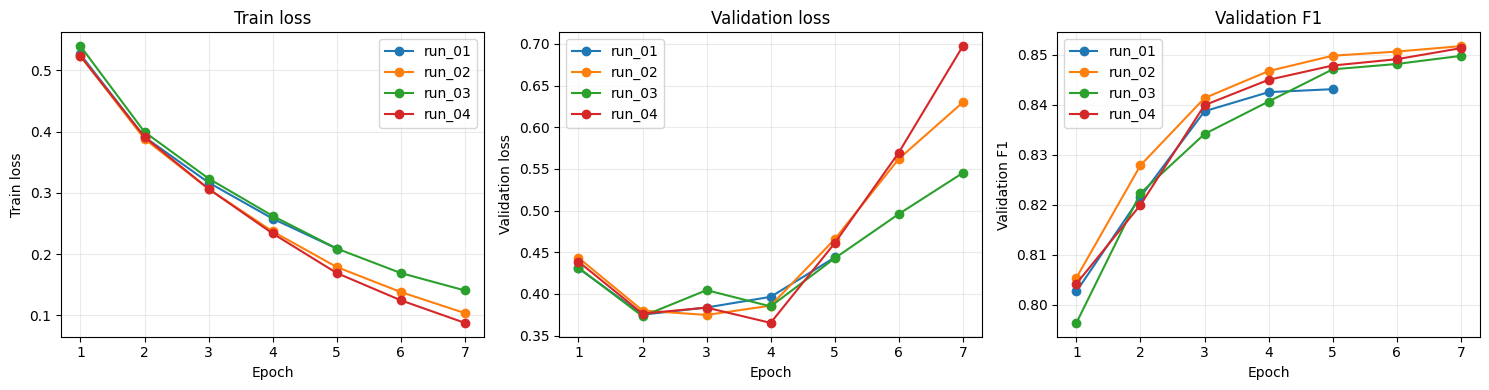

**run_01**: train loss 0.5257 ? 0.2090; validation loss 0.4308 ? 0.4438; highest epoch validation F1 at epoch 5.

Training loss falls while validation loss finishes above its minimum: this is consistent with possible overfitting. F1 and loss can move differently because F1 uses discrete predictions, whereas loss also reflects confidence. This observation does not change the selection criterion.

**run_02**: train loss 0.5230 ? 0.1038; validation loss 0.4434 ? 0.6299; highest epoch validation F1 at epoch 7.

Training loss falls while validation loss finishes above its minimum: this is consistent with possible overfitting. F1 and loss can move differently because F1 uses discrete predictions, whereas loss also reflects confidence. This observation does not change the selection criterion.

**run_03**: train loss 0.5392 ? 0.1408; validation loss 0.4315 ? 0.5452; highest epoch validation F1 at epoch 7.

Training loss falls while validation loss finishes above its minimum: this is consistent with possible overfitting. F1 and loss can move differently because F1 uses discrete predictions, whereas loss also reflects confidence. This observation does not change the selection criterion.

**run_04**: train loss 0.5229 ? 0.0879; validation loss 0.4388 ? 0.6973; highest epoch validation F1 at epoch 7.

Training loss falls while validation loss finishes above its minimum: this is consistent with possible overfitting. F1 and loss can move differently because F1 uses discrete predictions, whereas loss also reflects confidence. This observation does not change the selection criterion.

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name in RUN_NAMES:
    table = epoch_table(name)
    for ax, column, title in zip(axes, ['train_loss', 'eval_loss', 'eval_f1'],
                                  ['Train loss', 'Validation loss', 'Validation F1']):
        values = table[column].dropna()
        ax.plot(values.index, values.values, marker='o', label=name)
        ax.set(xlabel='Epoch', ylabel=title, title=title)
        ax.grid(alpha=0.25)
        ax.legend()
fig.tight_layout()
plt.show()
for name in RUN_NAMES:
    t = epoch_table(name)
    best_epoch = t['eval_f1'].idxmax()
    train = t['train_loss'].dropna()
    val = t['eval_loss'].dropna()
    display(Markdown(f"**{name}**: train loss {train.iloc[0]:.4f} ? {train.iloc[-1]:.4f}; "
                     f"validation loss {val.iloc[0]:.4f} ? {val.iloc[-1]:.4f}; "
                     f"highest epoch validation F1 at epoch {best_epoch:g}."))
    if train.iloc[-1] < train.iloc[0] and val.iloc[-1] > val.min():
        display(Markdown('Training loss falls while validation loss finishes above its minimum: '
                         'this is consistent with possible overfitting. F1 and loss can move '
                         'differently because F1 uses discrete predictions, whereas loss also '
                         'reflects confidence. This observation does not change the selection criterion.'))


## 8. Controlled comparison summary
Highlight the highest validation F1 programmatically; no test metrics are used.


In [11]:
summary = comparison(RUN_NAMES)
display(summary.style.format(precision=6).highlight_max(subset=['best_validation_f1'], color='#d9ead3'))


,learning_rate,max_epochs,batch_size,best_validation_accuracy,best_validation_precision,best_validation_recall,best_validation_f1
run,,,,,,,
run_01,0.000020,5,32,0.845029,0.853558,0.832968,0.843137
run_02,0.000030,7,32,0.851882,0.852591,0.850877,0.851733
run_03,0.000020,7,32,0.850055,0.851275,0.848319,0.849794
run_04,0.000040,7,32,0.852431,0.857726,0.845029,0.851330


## 9. Final BERT selection
Select the highest validation F1 without forcing an expected winner. These are single-seed experiments, so small differences do not establish statistical significance.


In [12]:
selected = summary['best_validation_f1'].idxmax()
c = runs[selected]['config']
model_path = Path('models/bert') / selected / 'best_model'
display(Markdown(f"Selected **{selected}**, validation F1 **{summary.loc[selected, 'best_validation_f1']:.6f}**. "
                 f"Configuration: **{c['model_name']}**, LR **{c['learning_rate']:g}**, "
                 f"maximum **{c['max_epochs']} epochs**, batch size **{c['batch_size']}**. "
                 f"Selected checkpoint: `{model_path.as_posix()}`."))
if selected == 'run_02' and f1.run_03 > f1.run_01 and f1.run_02 > f1.run_03 and f1.run_04 <= f1.run_02:
    display(Markdown('Run 03 shows that additional training budget improved the 2e-5 configuration. '
                     'Moving to 3e-5 improved F1 further; 4e-5 brought no additional improvement. '
                     'These results suggest diminishing returns or a plateau around 3e-5 to 4e-5. '
                     'Run 02 has the highest validation F1 and is selected.'))
else:
    display(Markdown('The observed results differ from the anticipated experimental narrative. '
                     'Use the tables above and the actual validation-F1 winner; do not force Run 02.'))


Selected **run_02**, validation F1 **0.851733**. Configuration: **bert-base-uncased**, LR **3e-05**, maximum **7 epochs**, batch size **32**. Selected checkpoint: `models/bert/run_02/best_model`.

Run 03 shows that additional training budget improved the 2e-5 configuration. Moving to 3e-5 improved F1 further; 4e-5 brought no additional improvement. These results suggest diminishing returns or a plateau around 3e-5 to 4e-5. Run 02 has the highest validation F1 and is selected.

## 10. Methodological conclusion
BERT hyperparameter exploration is now closed. No further BERT tuning will be performed
based on SUM test or UMWP results. Untouched SUM test data will be used once for final
in-distribution evaluation; UMWP is an external generalization benchmark. Any future
fresh/private dataset is also evaluation-only. Test performance must not influence
BERT checkpoints or hyperparameter selection.
